In [1]:
%load_ext autoreload
%autoreload 2



In [10]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import actual_vs_prediction, feature_importance, y_fdistro


In [11]:
COLUMNS_DIR = "bioactivity_columns.json"

In [1]:
df = DataManager(path='bioactivity/egfr').dataset

with open(COLUMNS_DIR, "r") as f:
    data = json.load(f)

df = df[data["columns"]]
len(df.columns)

NameError: name 'DataManager' is not defined

In [16]:
fp_cols = [col for col in df.columns if col.startswith('fp_')]
uniques_cols = df[fp_cols].nunique()
constant_cols = uniques_cols[uniques_cols == 1]
df = df.drop(columns=constant_cols.index)

exclude_column(path=COLUMNS_DIR, col_name="egfr_exclusion", col=list(constant_cols.index))

In [17]:
null = df.isnull().sum().sum()
df

,mol_weight,logp,tpsa,num_h_donors,num_h_acceptors,num_rotatable_bonds,num_aromatic_rings,num_rings,num_heavy_atoms,fraction_csp3,...,fp_1015,fp_1016,fp_1017,fp_1018,fp_1019,fp_1020,fp_1021,fp_1022,fp_1023,pIC50
0,383.814,4.45034,82.70,3,4,3,3,4,27,0.105263,...,0,0,0,0,0,0,0,0,1,7.3872
1,482.903,3.61432,112.24,3,6,4,3,5,34,0.217391,...,0,0,0,0,0,0,0,0,0,6.7696
2,369.432,4.77200,78.66,1,6,6,4,4,28,0.095238,...,0,0,0,0,0,0,0,0,0,5.0315
3,215.168,1.73096,110.95,1,5,2,1,1,16,0.000000,...,0,0,0,0,0,0,0,0,0,4.0177
4,539.999,3.22822,115.48,3,7,7,3,5,38,0.307692,...,0,0,0,0,0,0,0,0,0,5.2749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2080,428.517,5.97572,69.16,1,7,5,5,5,31,0.125000,...,0,0,0,0,0,0,0,0,0,6.6198
2081,444.516,5.67590,78.39,1,8,6,5,5,32,0.125000,...,0,0,0,0,0,0,0,0,0,7.2007
2082,508.630,4.35850,110.77,2,7,5,5,7,38,0.379310,...,0,0,0,0,1,0,0,0,0,6.5686
2083,514.659,4.42000,110.77,2,8,5,5,7,37,0.407407,...,0,0,0,0,1,0,0,0,0,6.4425


In [18]:
X = df.drop(columns='pIC50')
y = df['pIC50']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=25)
len(df.columns)

1029

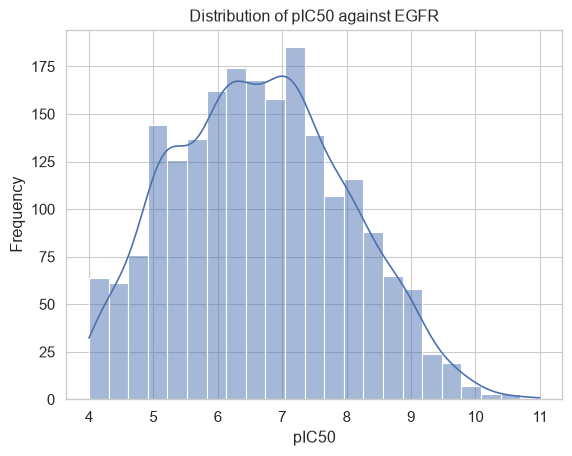

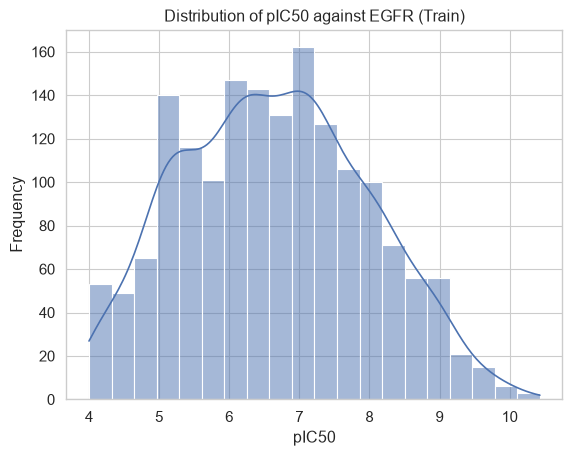

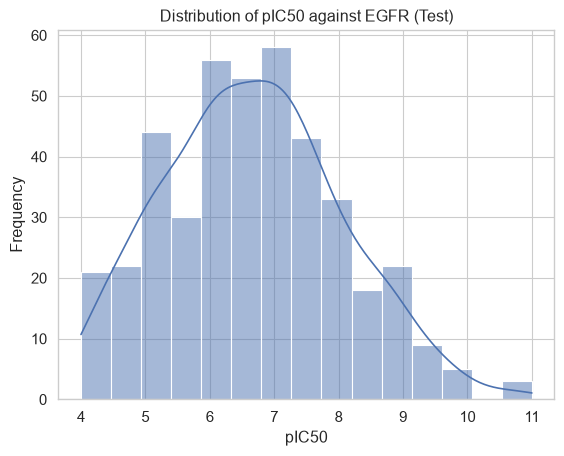

In [19]:
y_fdistro(y, "pIC50 against EGFR")
y_fdistro(y_train, "pIC50 against EGFR (Train)")
y_fdistro(y_test, "pIC50 against EGFR (Test)")

In [9]:
model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [1500, 2000, 2500],
    "max_depth": [None, 5, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
    "max_samples": [None, 0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)



{'n_estimators': 2500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_samples': None, 'max_features': 0.8, 'max_depth': 30}
-0.7403341022051982


In [21]:
best_model = RandomForestRegressor(
    n_estimators=2500,
    min_samples_split=2,
    min_samples_leaf=2,
    max_samples=None,
    max_features=0.8,
    max_depth=30
)

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [22]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')

RMSE: 0.7535919526628861
MSE: 0.5679008311182616
MAE: 0.5775479212655431
R2: 0.6956736071198795


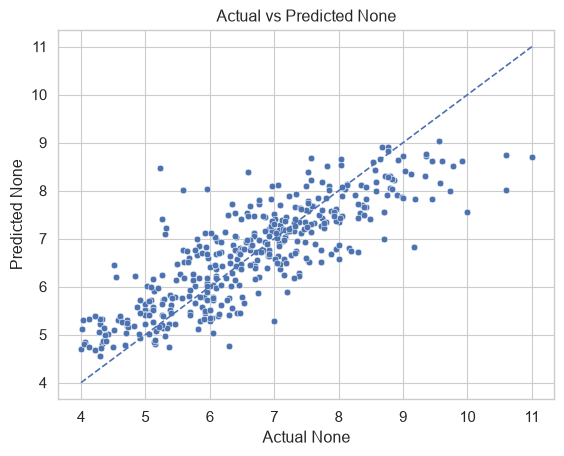

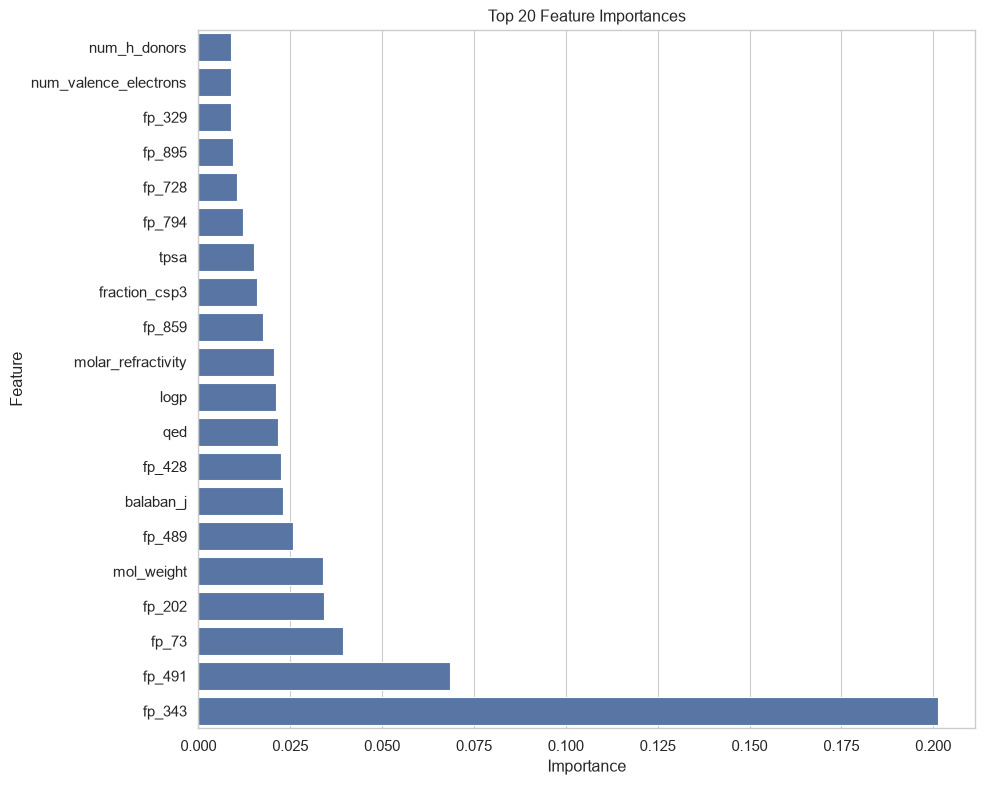

,Feature,Importance
3,num_h_donors,0.008895
10,num_valence_electrons,0.008927
342,fp_329,0.008943
901,fp_895,0.009483
736,fp_728,0.010596
802,fp_794,0.012092
2,tpsa,0.015247
9,fraction_csp3,0.015974
867,fp_859,0.017577
11,molar_refractivity,0.020572


In [23]:
importances = pd.DataFrame({
    "Features Importance": X_train.columns,
    "Importances": best_model.feature_importances_
})
actual_vs_prediction(y_test, y_pred)
feature_importance(best_model, X_train.columns, 20)